# Bank Well - Build 2026
## Statsitics

In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [83]:
UK_CHURCHES_PATH = "ftbuild-bank-well-church-switch/uk_churches.csv"

In [84]:
df = pd.read_csv(UK_CHURCHES_PATH)
df = df[df["income"] > 0]
df.head()

,charity_name,registered_number,contact_postcode,contact_web,income,expenditure,denomination,principal_bank,reserves,assets_total,assets_cash,funds_total
0,HITCHAM FREE CHURCH,200027,NaN,NaN,93073.0,264019.0,Non‑denominational,Caf Bank,2024499.0,2077693.0,30731.0,2838807.0
1,MELLS CHURCH LANDS,200999,NaN,NaN,10232.0,5511.0,Church of England,NaN,NaN,NaN,NaN,NaN
3,CHURCH AND POOR LANDS FOR PARISH OF ST JOHN,201444,NaN,NaN,29224.0,13918.0,Church of England,Lloyds,NaN,NaN,NaN,NaN
7,THE PARISH LANDS CHARITY (IN THE ANCIENT PARIS...,203004,NaN,NaN,47655.0,56806.0,Unknown,NaN,NaN,NaN,NaN,NaN
9,CHURCH LANDS ECCLESIASTICAL CHARITY,203336,NaN,NaN,89708.0,76344.0,Church of England,Bank Of Scotland,NaN,NaN,NaN,NaN


The total cash assets is only reported for churches with higher levels of income:

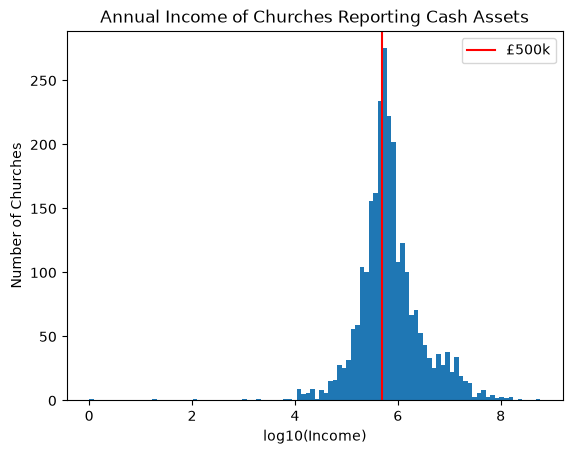

In [85]:
plt.hist(np.log10(df[~df["assets_cash"].isna()]["income"]), bins=100)
plt.axvline(np.log10(500000), color="red", label="£500k")
plt.title("Annual Income of Churches Reporting Cash Assets")
plt.xlabel("log10(Income)")
plt.ylabel("Number of Churches")
plt.legend()
plt.show()

Additional cash assets data was extracted from PDFs. The data from the PDFs represents churches with lower income overall:

Missing assets_cash filled from PDFs: 4840 of 25927


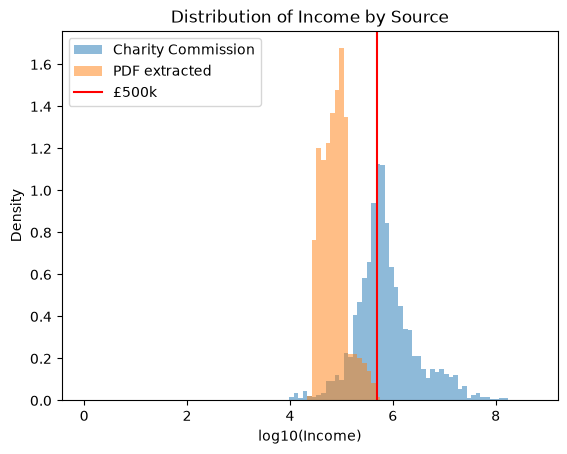

In [86]:
pdf = pd.read_csv("pdf_extract_final.csv", encoding="utf-8-sig")
df = df.merge(pdf[["registered_number", "assets_cash"]].rename(columns={"assets_cash": "assets_cash_pdf"}), on="registered_number", how="left")
filled = df["assets_cash"].isna() & df["assets_cash_pdf"].notna()
print(f"Missing assets_cash filled from PDFs: {filled.sum()} of {df['assets_cash'].isna().sum()}")

original = np.log10(df.loc[df["assets_cash"].notna(), "income"])
extracted = np.log10(df.loc[filled, "income"])
bins = np.linspace(min(original.min(), extracted.min()), max(original.max(), extracted.max()), 100)
plt.hist(original, bins=bins, density=True, alpha=0.5, label="Charity Commission")
plt.hist(extracted, bins=bins, density=True, alpha=0.5, label="PDF extracted")
plt.axvline(np.log10(500000), color="red", label="£500k")
plt.title("Distribution of Income by Source")
plt.xlabel("log10(Income)")
plt.ylabel("Density")
plt.legend()
plt.show()

## Correlations with Cash Assets
Correlation of income and expenditure with total cash assets. Pearson is calculated on log10 values; Spearman on raw values.

Charity Commission: 2550 churches
Pearson (log10):
income         0.489
expenditure    0.502
Name: assets_cash, dtype: float64
Spearman:
income         0.434
expenditure    0.430
Name: assets_cash, dtype: float64
Income vs expenditure: Pearson (log10) 0.862, Spearman 0.860


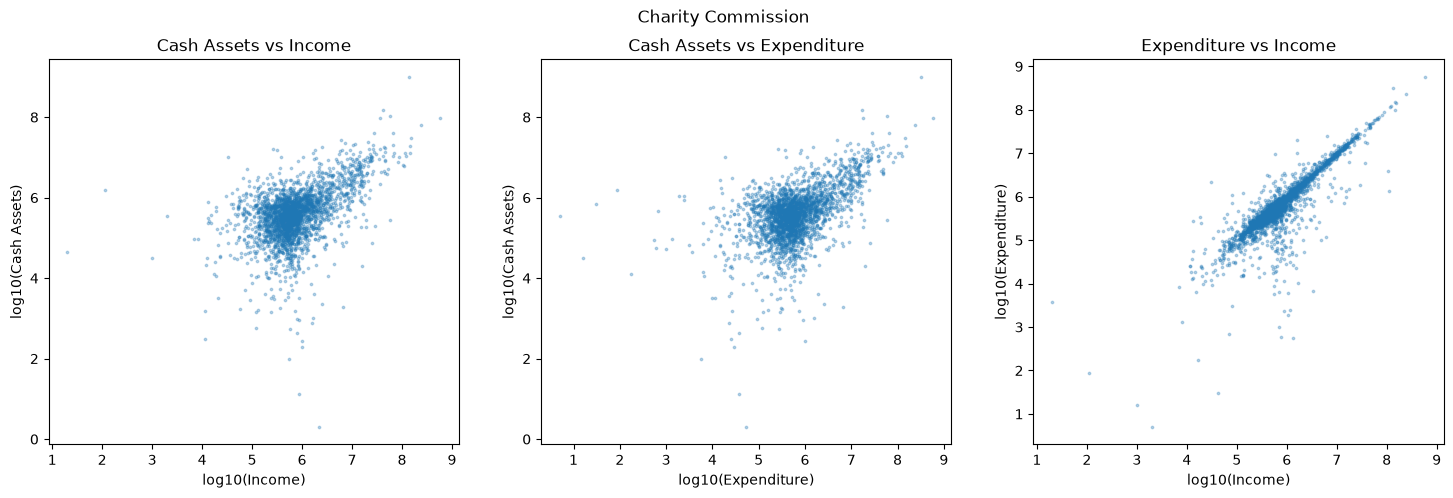

In [87]:
cc = df.loc[df["assets_cash"].notna(), ["income", "expenditure", "assets_cash"]].rename(columns={"assets_cash": "assets_cash"})
cc = cc[(cc > 0).all(axis=1)]
print(f"Charity Commission: {len(cc)} churches")
print("Pearson (log10):")
print(np.log10(cc).corr()["assets_cash"].drop("assets_cash").round(3))
print("Spearman:")
print(cc.corr(method="spearman")["assets_cash"].drop("assets_cash").round(3))
print(f"Income vs expenditure: Pearson (log10) {np.log10(cc['income']).corr(np.log10(cc['expenditure'])):.3f}, Spearman {cc[['income', 'expenditure']].corr(method='spearman').iloc[0, 1]:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["income", "expenditure"]):
    ax.scatter(np.log10(cc[col]), np.log10(cc["assets_cash"]), s=3, alpha=0.3)
    ax.set_xlabel(f"log10({col.capitalize()})")
    ax.set_title(f"Cash Assets vs {col.capitalize()}")
axes[0].set_ylabel("log10(Cash Assets)")
axes[1].set_ylabel("log10(Cash Assets)")
axes[2].scatter(np.log10(cc["income"]), np.log10(cc["expenditure"]), s=3, alpha=0.3)
axes[2].set_xlabel("log10(Income)")
axes[2].set_ylabel("log10(Expenditure)")
axes[2].set_title("Expenditure vs Income")
fig.suptitle("Charity Commission")
plt.show()

PDF extracted: 4816 churches
Pearson (log10):
income         0.299
expenditure    0.157
Name: assets_cash, dtype: float64
Spearman:
income         0.330
expenditure    0.237
Name: assets_cash, dtype: float64
Income vs expenditure: Pearson (log10) 0.729, Spearman 0.818


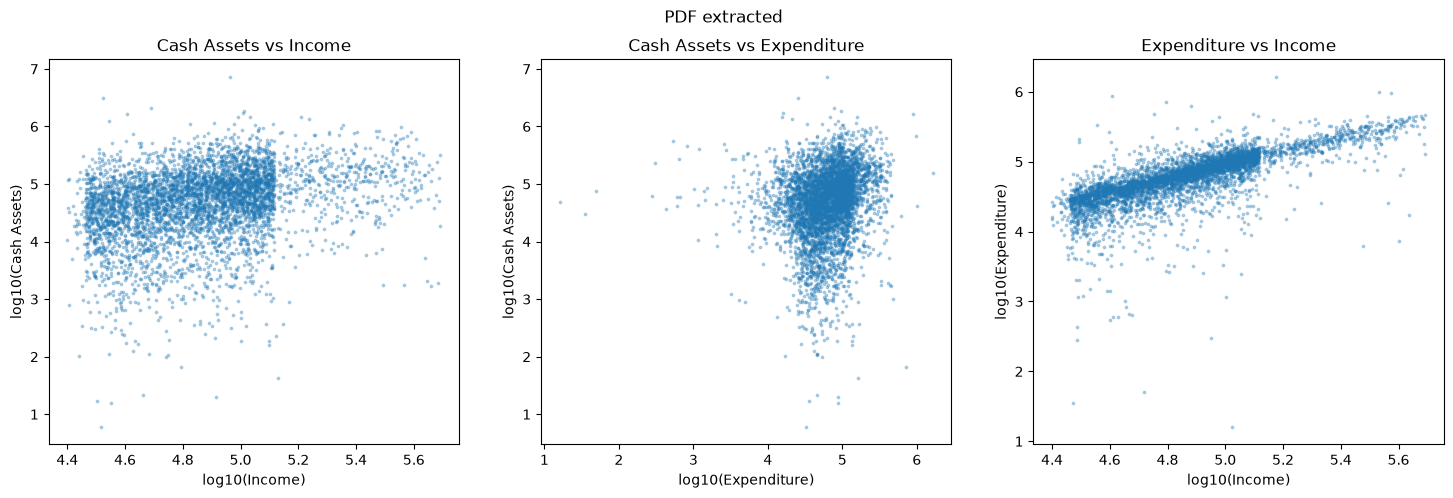

In [88]:
pdf_ex = df.loc[filled, ["income", "expenditure", "assets_cash_pdf"]].rename(columns={"assets_cash_pdf": "assets_cash"})
pdf_ex = pdf_ex[(pdf_ex > 0).all(axis=1)]
print(f"PDF extracted: {len(pdf_ex)} churches")
print("Pearson (log10):")
print(np.log10(pdf_ex).corr()["assets_cash"].drop("assets_cash").round(3))
print("Spearman:")
print(pdf_ex.corr(method="spearman")["assets_cash"].drop("assets_cash").round(3))
print(f"Income vs expenditure: Pearson (log10) {np.log10(pdf_ex['income']).corr(np.log10(pdf_ex['expenditure'])):.3f}, Spearman {pdf_ex[['income', 'expenditure']].corr(method='spearman').iloc[0, 1]:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["income", "expenditure"]):
    ax.scatter(np.log10(pdf_ex[col]), np.log10(pdf_ex["assets_cash"]), s=3, alpha=0.3)
    ax.set_xlabel(f"log10({col.capitalize()})")
    ax.set_title(f"Cash Assets vs {col.capitalize()}")
axes[0].set_ylabel("log10(Cash Assets)")
axes[1].set_ylabel("log10(Cash Assets)")
axes[2].scatter(np.log10(pdf_ex["income"]), np.log10(pdf_ex["expenditure"]), s=3, alpha=0.3)
axes[2].set_xlabel("log10(Income)")
axes[2].set_ylabel("log10(Expenditure)")
axes[2].set_title("Expenditure vs Income")
fig.suptitle("PDF extracted")
plt.show()

## Estimated Cash Assets by Denomination
Missing cash assets are estimated using the mean PDF-extracted cash assets within each income band (£25k-£500k). Churches with income below £25k have no PDF data and are excluded from the estimates.

In [89]:
df["assets_cash_known"] = df["assets_cash"].fillna(df["assets_cash_pdf"])
df["income_band"] = pd.cut(df["income"], [25_000, 50_000, 100_000, 150_000, 250_000, 500_000])
band_means = df[filled].groupby("income_band", observed=True)["assets_cash_pdf"].agg(["count", "mean"])
band_means

,count,mean
income_band,,
"(25000, 50000]",1383,59797.100383
"(50000, 100000]",2039,97124.466282
"(100000, 150000]",1017,121222.232262
"(150000, 250000]",217,180297.258065
"(250000, 500000]",184,185072.173913


In [90]:
to_estimate = df["assets_cash_known"].isna() & df["income_band"].notna()
df["assets_cash_est"] = df.loc[to_estimate, "income_band"].map(band_means["mean"]).astype(float)
print(f"Estimated: {to_estimate.sum()} churches")
print(f"Excluded (no cash data, income outside £25k-£500k): {(df['assets_cash_known'].isna() & ~to_estimate).sum()} churches")

by_denomination = df.groupby("denomination").agg(
    churches=("registered_number", "count"),
    known_cash=("assets_cash_known", "sum"),
    estimated_cash=("assets_cash_est", "sum"),
)
by_denomination["total_cash"] = by_denomination["known_cash"] + by_denomination["estimated_cash"]
by_denomination = by_denomination.sort_values("total_cash", ascending=False)
by_denomination.loc["Total"] = by_denomination.sum()
by_denomination[["known_cash", "estimated_cash", "total_cash"]] = (by_denomination[["known_cash", "estimated_cash", "total_cash"]] / 1e6).round(1)
by_denomination.rename(columns={"known_cash": "known_cash_£m", "estimated_cash": "estimated_cash_£m", "total_cash": "total_cash_£m"})

Estimated: 7902 churches
Excluded (no cash data, income outside £25k-£500k): 13185 churches


,churches,known_cash_£m,estimated_cash_£m,total_cash_£m
denomination,,,,
Church of England,7383.0,1777.5,297.3,2074.8
Unknown,10536.0,981.3,256.5,1237.8
Roman Catholic,885.0,705.7,23.4,729.1
Non-denominational,2275.0,323.4,74.1,397.5
Baptist,1189.0,143.4,74.4,217.8
...,...,...,...,...
Church,1.0,0.0,0.0,0.0
Church of Wales,3.0,0.0,0.0,0.0
Church ofEngland,1.0,0.0,0.0,0.0


## Export
Exports the PDF-extracted and estimated cash assets for each church.

In [91]:
export = df[["registered_number", "assets_cash_pdf", "assets_cash_est"]].rename(columns={"assets_cash_est": "assets_cash_estimated"})
export.to_csv("cash_assets_estimates.csv", index=False)
print(f"Exported {len(export)} rows to cash_assets_estimates.csv")

Exported 28529 rows to cash_assets_estimates.csv
